In [1]:
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

In [2]:
df = pd.read_csv("clean_data.csv")

## **1. Data Distribution**

In [3]:
# Sepearting categorical and numerical distribution

numerical_columns = df.select_dtypes(include=["number"]).columns.to_list()
categorical_columns = df.select_dtypes(include=["object"]).columns.to_list()

# Remove date from categorical columns
categorical_columns.remove("date")

print(f"Numerical Columns #: {len(numerical_columns)}")
print(f"Categorical Columns #: {len(categorical_columns)}")

Numerical Columns #: 20
Categorical Columns #: 3


/tmp/ipykernel_19604/4017716853.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object"]).columns.to_list()


### **1.1. Numerical Distribution**

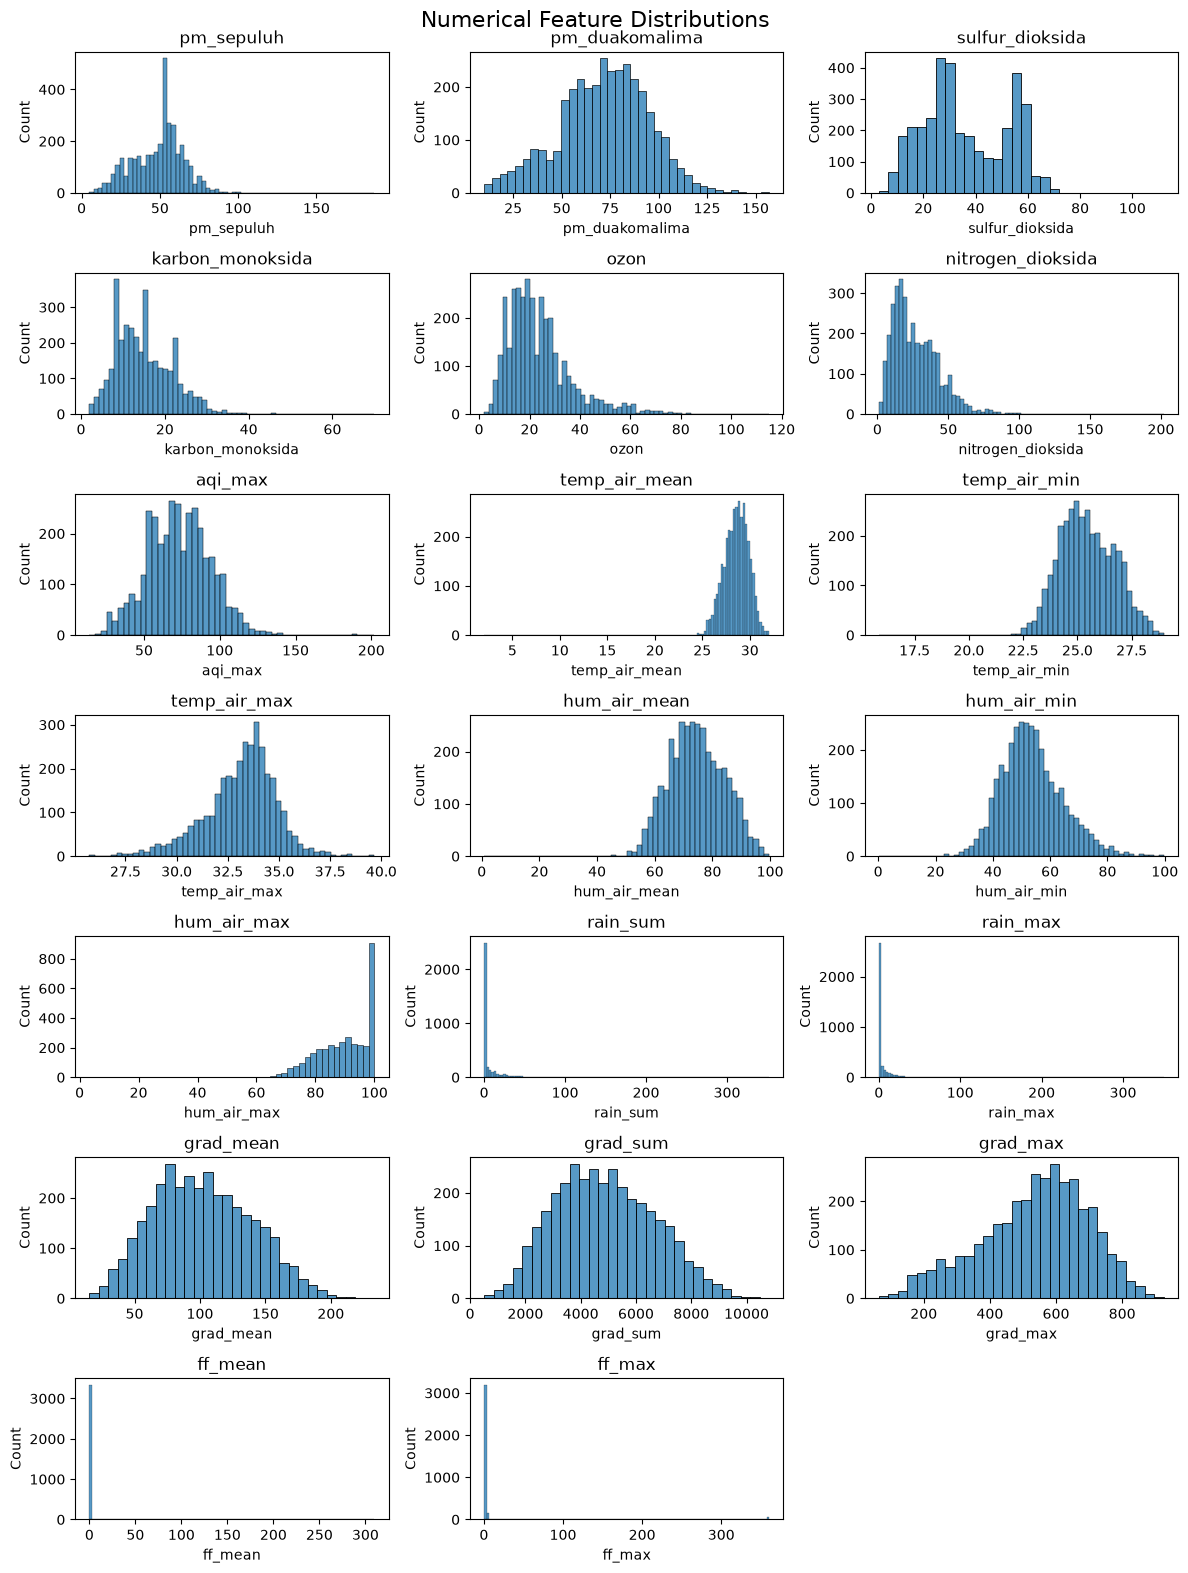

In [4]:
def numeric_dist(df: pd.DataFrame, numCols: list[str]) -> None:
    plots_needed = len(numCols)
    
    ncols = 3
    nrows = -(-plots_needed//ncols)
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 16))
    
    
    for ax, col in zip(axes.flatten(), numCols):
        sns.histplot(data=df, x=col, ax=ax)
        ax.set_title(f"{col}")
    
    for ax in axes.flatten()[plots_needed:]:
        ax.set_visible(False)
    
    plt.suptitle("Numerical Feature Distributions", fontsize=16)
    
    plt.tight_layout()
    plt.show()

numeric_dist(df, numerical_columns)

### **1.2 Categorical Distribution**

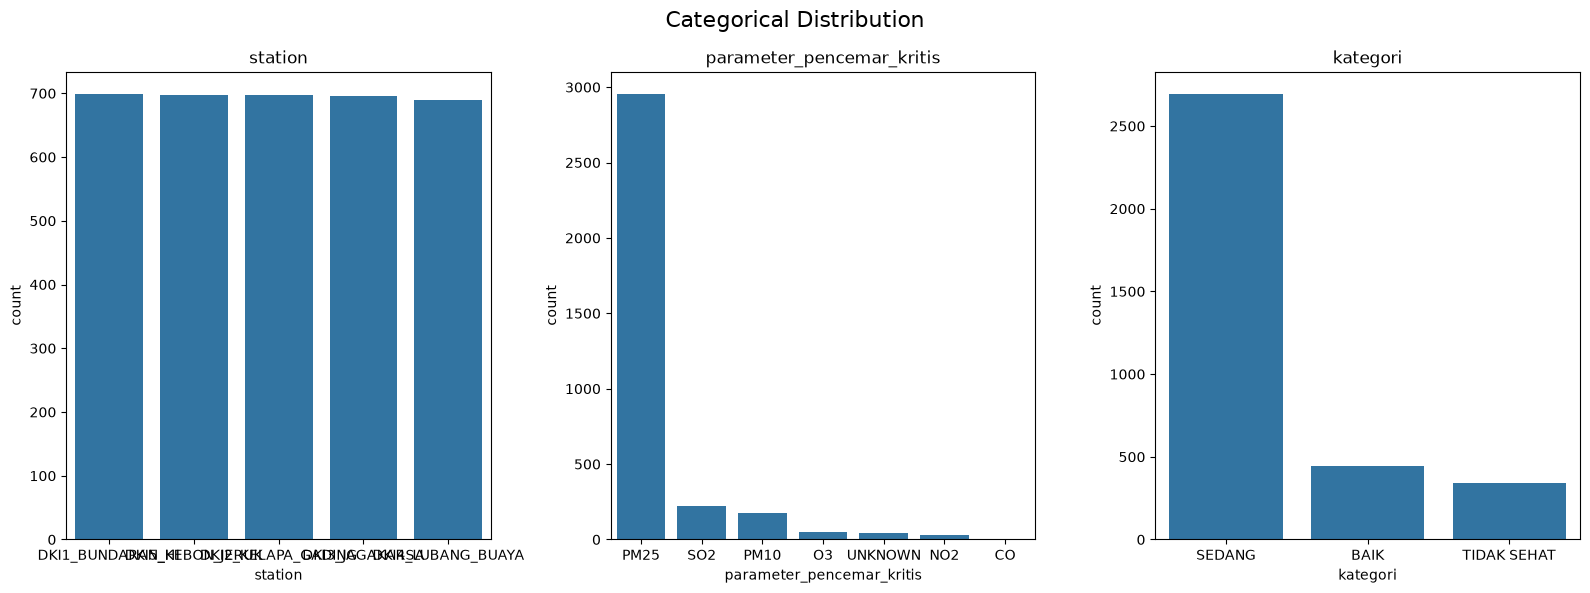

In [5]:
def cat_dist(df: pd.DataFrame, catCols: list[str]) -> None:
    plots_needed = len(catCols)
    ncols = 3
    nrows = -(-plots_needed//ncols)
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 6))
    
    for ax, col in zip(axes.flatten(), catCols):
        sns.countplot(data=df, x=col ,ax=ax, order=df[col].value_counts().index)
        ax.set_title(f"{col}")
    
    for ax in axes.flatten()[plots_needed:]:
        ax.set_visible(False)
        
    fig.suptitle("Categorical Distribution", fontsize=16)
    plt.tight_layout()
    plt.show()

cat_dist(df, categorical_columns)
        

## 2. **Average Weather Condition for Each Air Quality Categories**

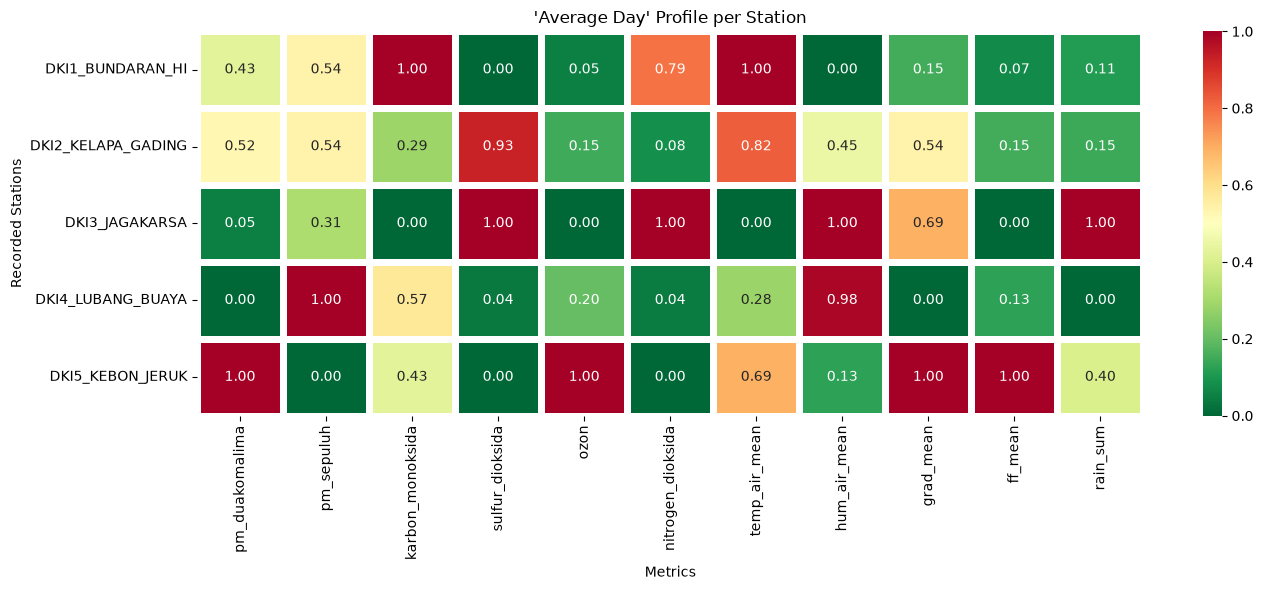

In [6]:
# Create profile for each station
weather_profile = [
    # Pollutant Levels
    "pm_duakomalima", "pm_sepuluh",
    "karbon_monoksida", "sulfur_dioksida", "ozon", "nitrogen_dioksida",
    
    # Weather Conditions
    "temp_air_mean", "hum_air_mean", "grad_mean", "ff_mean",
]

agg_dict = {col: 'median' for col in weather_profile}
agg_dict['rain_sum'] = 'mean'


df_average_day = df.groupby('station').agg(agg_dict)



# Normalize using min max
scaled = df_average_day.copy()

for col in scaled.columns:
    scaled[col] = (scaled[col] - scaled[col].min()) / (scaled[col].max() - scaled[col].min())


    
plt.figure(figsize=(14, 6))
sns.heatmap(scaled, cmap='RdYlGn_r', linewidths=5, fmt=".2f", annot=True)
plt.title("'Average Day' Profile per Station")
plt.ylabel("Recorded Stations")
plt.xlabel("Metrics")
plt.tight_layout()
plt.show()




### **3. Which Station Has The Worst Air Quality?**

In [7]:
df.groupby('station')['kategori'].value_counts().reset_index()

,station,kategori,count
0,DKI1_BUNDARAN_HI,SEDANG,547
1,DKI1_BUNDARAN_HI,BAIK,107
2,DKI1_BUNDARAN_HI,TIDAK SEHAT,45
3,DKI2_KELAPA_GADING,SEDANG,548
4,DKI2_KELAPA_GADING,BAIK,80
5,DKI2_KELAPA_GADING,TIDAK SEHAT,69
6,DKI3_JAGAKARSA,SEDANG,628
7,DKI3_JAGAKARSA,BAIK,34
8,DKI3_JAGAKARSA,TIDAK SEHAT,34
9,DKI4_LUBANG_BUAYA,SEDANG,499


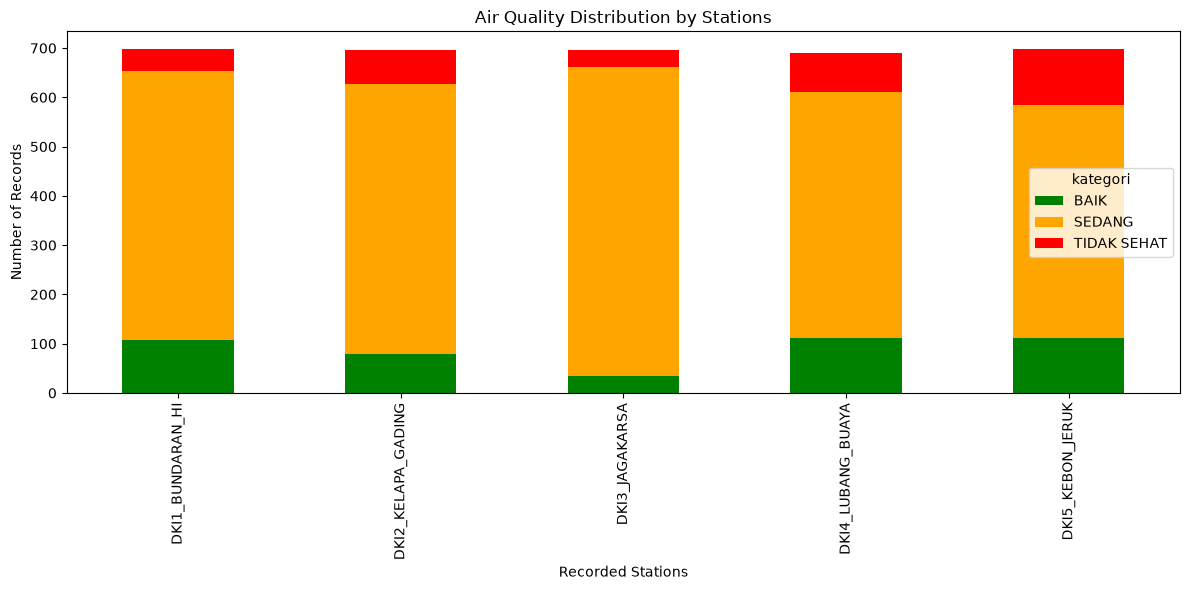

In [8]:
def station_dist(df: pd.DataFrame, targetCol: str) -> None:
    
    df_agg = df.groupby(targetCol)['kategori'].value_counts().unstack()
    
    df_agg.plot(kind='bar', stacked='true', color=['green', 'orange', 'red'], figsize=(12, 6))
    
    plt.title("Air Quality Distribution by Stations")
    plt.xlabel("Recorded Stations")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()
        
     
station_dist(df, "station")       
    

## **4. Monthly Average PM2.5 per Station**

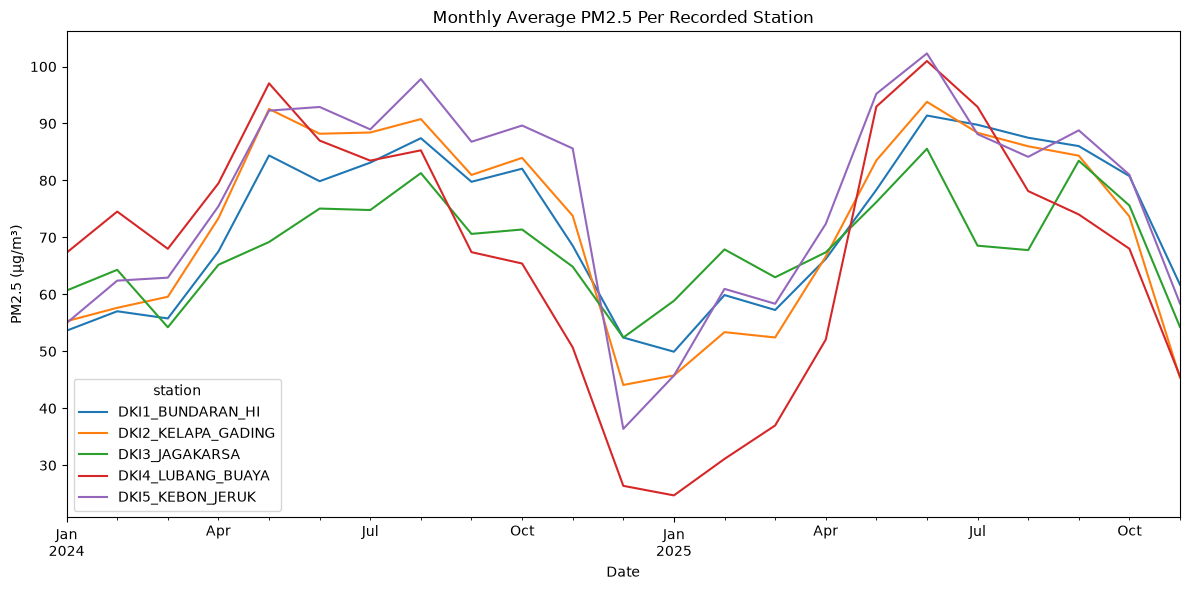

In [18]:
# Convert date type first
df['date'] = pd.to_datetime(df['date'])

df_pm25 = df.groupby([df['date'].dt.to_period('M'), 'station'])['pm_duakomalima'].mean().unstack()

ax = df_pm25.plot(figsize=(12, 6))
ax.set_title("Monthly Average PM2.5 Per Recorded Station")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()

# **Correlation Analysis**

### **1. Contingency Table**

In [28]:
from scipy.stats import chi2_contingency

alpha = 0.05

# 1. Build Contingency Table
ct = pd.crosstab(df['parameter_pencemar_kritis'], df['kategori'])

print(ct)

kategori                   BAIK  SEDANG  TIDAK SEHAT
parameter_pencemar_kritis                           
CO                            1       0            0
NO2                           5      21            1
O3                           26      25            1
PM10                         91      82            3
PM25                        258    2364          333
SO2                          62     162            1
UNKNOWN                       1      40            3


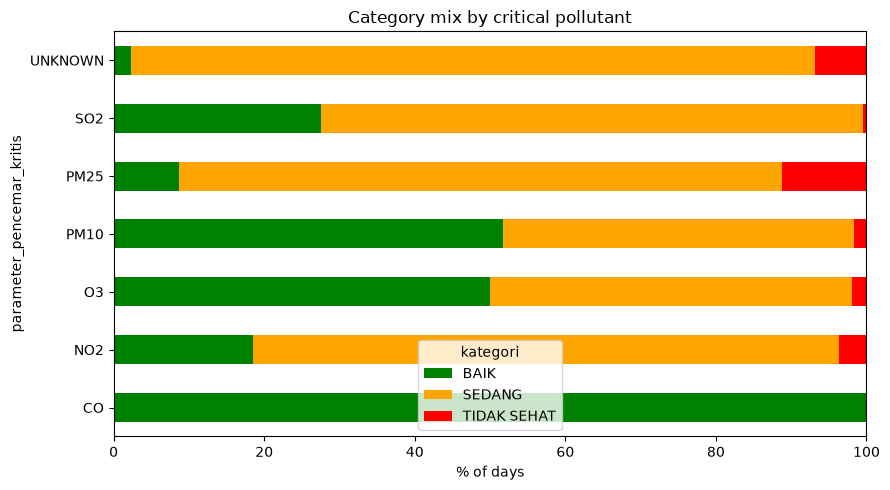

In [27]:
pct = pd.crosstab(df['parameter_pencemar_kritis'], df['kategori'], normalize='index') * 100
pct.plot(kind='barh', stacked=True, color=['green', 'orange', 'red'], figsize=(9, 5))
plt.xlabel('% of days')
plt.title('Category mix by critical pollutant')
plt.tight_layout()
plt.show()

### **2. Spearman Correlation**

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3480 entries, 0 to 3479
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   date                       3480 non-null   datetime64[us]
 1   station                    3480 non-null   str           
 2   pm_sepuluh                 3480 non-null   float64       
 3   pm_duakomalima             3480 non-null   float64       
 4   sulfur_dioksida            3480 non-null   float64       
 5   karbon_monoksida           3480 non-null   float64       
 6   ozon                       3480 non-null   float64       
 7   nitrogen_dioksida          3480 non-null   float64       
 8   aqi_max                    3480 non-null   float64       
 9   parameter_pencemar_kritis  3480 non-null   str           
 10  kategori                   3480 non-null   str           
 11  temp_air_mean              3480 non-null   float64       
 12  temp_air_min     

In [ ]:
from scipy.stats import spearmanr

weather_columns = ['temp_air_mean', 'hum_air_mean', 'rain_sum', 'grad_mean', 'ff_mean']
target_column = 'pm_duakomalima'

for col in weather_columns:
    spearman_coeff = df[target_column].corr(df[col], method='spearman')
    print(f"{col}: {spearman_coeff}")



temp_air_mean: 0.35128632315134595
hum_air_mean: -0.3102197110920055
rain_sum: -0.2673380424769809
grad_mean: 0.09180946035349284
ff_mean: -0.1432653858795537
